# Week 1: Causal graphs with DoWhy

**Question:** What extra response does an email cause, compared with sending no email?

This notebook completes the Week 1 causal-graph task in the supplied project images and *EconoCausal Project Guide*. It contains two clearly separated examples:

1. **Real Hillstrom experiment:** randomized men's email, women's email, and no email. Identify both email-versus-control effects for visits, purchases, and spending.
2. **Mock retail example required by the images:** past spending influences both offer assignment and future spending. Show why adjusting for this measured confounder matters.

The earlier graph's basic distinction was correct, but it only identified one email/outcome comparison and required helper files. This version covers six comparisons, draws the graphs, explains the assumptions, and runs without `common.py` or an existing processed CSV.

**Dataset fit:** the guide (sections 5-6 and 9) explicitly selects Hillstrom and allows email as the treatment. It contains no discount amounts, so we do not invent a $10-versus-$20 discount effect.

## 1. Setup

Open this repository folder in VS Code, select your Python 3.12 environment, and choose **Run All**. The raw CSV must be at `data/raw/hillstrom.csv`, which is already in this repository.

If the selected notebook kernel reports a missing package, run this in a new **notebook code cell**, then restart the kernel:

```python
%pip install "dowhy==0.14" pandas numpy scikit-learn matplotlib networkx
```

NetworkX draws the diagrams, so a separate Graphviz installation is not required. The code below saves its figures and results under `results/causal_graphs/` when you run it.

In [1]:
from pathlib import Path
import hashlib
import json
import logging

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
import dowhy
from dowhy import CausalModel
from sklearn.model_selection import train_test_split
from IPython.display import display

SEED = 42
BASELINE = ['recency', 'history', 'mens', 'womens', 'newbie', 'zip_code', 'channel']
OUTCOMES = ['visit', 'conversion', 'spend']
ARMS = {'No E-Mail': 0, 'Mens E-Mail': 1, 'Womens E-Mail': 2}

# Locate data from the project root or a notebook subfolder.
ROOT = next((folder for folder in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (folder / 'data/raw/hillstrom.csv').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Open the project folder containing data/raw/hillstrom.csv in VS Code.')
OUTPUT = ROOT / 'results/causal_graphs'
OUTPUT.mkdir(parents=True, exist_ok=True)
logging.getLogger('dowhy').setLevel(logging.ERROR)
print('DoWhy version:', dowhy.__version__)
print('Input: data/raw/hillstrom.csv')

DoWhy version: 0.14
Input: data/raw/hillstrom.csv


## 2. Check the source and reproduce the preprocessing split

The dataset has pre-campaign customer information, assigned email groups, and outcomes measured during the following two weeks. `mens` and `womens` are **past-purchase flags**; the email treatment is `segment`.

We keep duplicate-looking rows because there is no real customer ID to establish accidental copies. The generated `customer_id` below is only a row reference. This notebook uses the same seed, 70/30 split, treatment coding, and spelling correction as `02_preprocessing_feature_engineering.ipynb`. Only training rows enter the illustrative real-data estimates; the holdout outcomes remain unused.

In [2]:
raw_path = ROOT / 'data/raw/hillstrom.csv'
raw = pd.read_csv(raw_path)
required = BASELINE + ['segment'] + OUTCOMES
missing = sorted(set(required) - set(raw.columns))
if missing or raw.empty:
    raise ValueError(f'Empty data or missing columns: {missing}')
if raw[required].isna().any().any():
    raise ValueError('Missing required values: run the preprocessing checks before proceeding.')

numeric = ['recency', 'history', 'mens', 'womens', 'newbie'] + OUTCOMES
if not all(pd.api.types.is_numeric_dtype(raw[name]) for name in numeric):
    raise ValueError('Expected numeric baseline and outcome fields.')
if not np.isfinite(raw[numeric].to_numpy()).all():
    raise ValueError('Non-finite numeric value found.')
for name in ['mens', 'womens', 'newbie', 'visit', 'conversion']:
    if not raw[name].isin([0, 1]).all():
        raise ValueError(f'{name} must contain only 0/1.')
if not raw.segment.isin(ARMS).all():
    raise ValueError('Unexpected email assignment label.')
if not raw.recency.between(1, 12).all() or (raw.recency % 1 != 0).any():
    raise ValueError('Recency must be an integer from 1 to 12 months.')
if (raw[['history', 'spend']] < 0).any().any():
    raise ValueError('Spending cannot be negative.')
if (raw.conversion > raw.visit).any() or ((raw.spend > 0) != (raw.conversion == 1)).any():
    raise ValueError('Visit, purchase, and spend values disagree.')

data = raw.copy()
data['zip_code'] = data.zip_code.replace({'Surburban': 'Suburban'})
data['customer_id'] = [f'row_{i + 1:06d}' for i in range(len(data))]
data['treatment'] = data.segment.map(ARMS).astype(int)
train_ids, test_ids = train_test_split(
    np.arange(len(data)), test_size=0.30, stratify=data.treatment, random_state=SEED)
train = data.iloc[train_ids].copy()
assert set(train.customer_id).isdisjoint(set(data.iloc[test_ids].customer_id))

print(f'Rows: {len(raw):,}; training: {len(train):,}; reserved test: {len(test_ids):,}')
print(f'Duplicate-looking source rows retained: {raw.duplicated().sum():,}')
display(data.segment.value_counts().rename_axis('Email group').to_frame('Rows'))

Rows: 64,000; training: 44,800; reserved test: 19,200


Duplicate-looking source rows retained: 6,562


,Rows
Email group,
Womens E-Mail,21387
Mens E-Mail,21307
No E-Mail,21306


## 3. Identify the variable roles before drawing arrows

| Variable | Role | Why |
|---|---|---|
| `segment` / `treatment` | Assigned treatment | No email, men's email, or women's email |
| `visit` | Primary outcome | Website visit during the next two weeks |
| `conversion` | Secondary outcome | Purchase during the next two weeks |
| `spend` | Secondary outcome | Dollars spent during the next two weeks |
| `recency`, `history`, `mens`, `womens`, `newbie`, `zip_code`, `channel` | Pre-campaign predictors and possible effect modifiers | Can help explain customer response; treatment was randomized |
| `history_segment` | Redundant baseline representation | A bucketed version of past `history` |
| Generated `customer_id` | Join key only | Does not describe a customer's behavior |

A **confounder** affects both treatment assignment and the outcome; it can be measured or unmeasured. Being a good outcome predictor alone does not make a field a confounder.

The new engineered features `history_log1p`, `recency_band`, and `prior_interest_count` are deterministic transformations of the baseline variables. They can help the later DML model represent patterns; they do not add new treatment-assignment causes. We draw the original variables to keep the causal question readable.

For each outcome, use a separate DAG. When estimating the total email effect on `spend`, do not adjust for the later `visit` or `conversion`, and do not keep only visitors/buyers. That would condition on events occurring after treatment.

## 4. Real-data DAG: randomized email

Think of a teacher shuffling cards to choose who gets each email. Past purchases may predict who visits, but they did not determine the shuffled email assignment.

We draw baseline-feature arrows into the selected outcome and an email arrow into that outcome. There are **no baseline-feature arrows into treatment**. These are declared causal assumptions based on the documented randomized design, not facts proved by a correlation chart. Relationships among baseline variables are left unspecified in this simplified diagram; they do not create an incoming treatment path under randomization.

For a chosen email arm $a$, our average-effect target is:

$$ATE_a = E[Y(a) - Y(0)].$$

For a visit or purchase indicator, this is a probability difference. For spending, it is dollars per customer. This is an **average effect**, not an individual customer's observed counterfactual.

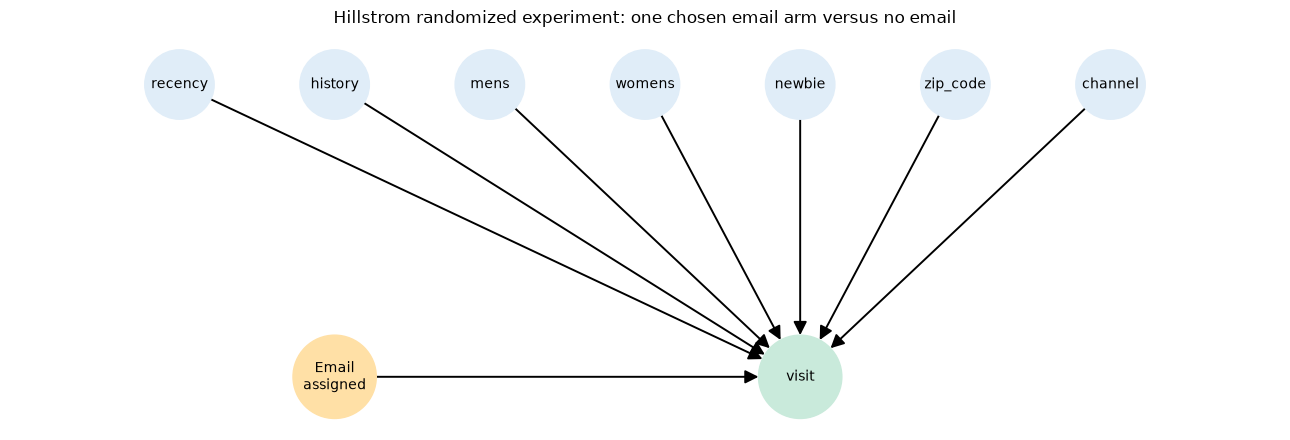

In [3]:
def make_email_graph(outcome):
    graph = nx.DiGraph()
    graph.add_edges_from((feature, outcome) for feature in BASELINE)
    graph.add_edge('email_received', outcome)
    return graph

# Draw a readable visit graph. The identical structure is used separately for the other outcomes.
visit_graph = make_email_graph('visit')
assert nx.is_directed_acyclic_graph(visit_graph)
assert visit_graph.in_degree('email_received') == 0
positions = {name: (i, 2) for i, name in enumerate(BASELINE)}
positions.update({'email_received': (1, 0), 'visit': (4, 0)})
fig, ax = plt.subplots(figsize=(13, 4.5))
colors = ['#e0edf8' if node in BASELINE else '#ffe0a6' if node == 'email_received' else '#c9eadb'
          for node in visit_graph.nodes]
nx.draw_networkx(visit_graph, pos=positions, ax=ax, node_color=colors,
                 node_size=[2500 if node in BASELINE else 3600 for node in visit_graph.nodes],
                 labels={node: ('Email\nassigned' if node == 'email_received' else node)
                         for node in visit_graph.nodes},
                 font_size=10, arrowsize=20, width=1.4)
ax.set_title('Hillstrom randomized experiment: one chosen email arm versus no email')
ax.margins(0.12)
ax.axis('off')
plt.tight_layout()
fig.savefig(OUTPUT / 'hillstrom_visit_dag.png', dpi=160, bbox_inches='tight')
plt.show()

## 5. Ask DoWhy to identify both email-versus-control effects

Do not interpret treatment codes `0, 1, 2` as a numeric dose: the two emails are different actions. We form two separate binary comparisons, each keeping its email arm and the shared no-email group:

- Men's email versus no email.
- Women's email versus no email.

Randomization gives each original arm a design probability of about one third; within either email/control pair, the assignment probability is one half. Observed counts can differ slightly by chance.

Within each pair, `email_received` is 1 for the chosen email and 0 for no email. We ask DoWhy to identify the effect separately for each of the three outcomes. Under the randomized DAG, the required backdoor adjustment set should be empty.

In simple terms: a backdoor path is a side route that mixes up who gets an offer with who would respond anyway. Random assignment blocks that route at the start. The two estimates share the same controls, so do not treat them as independent experiments in later statistical comparisons.

In [4]:
email_models = {}
email_estimands = {}
identification_rows = []
for arm_name, arm_code in [('Mens E-Mail', 1), ('Womens E-Mail', 2)]:
    pair = train[train.treatment.isin([0, arm_code])].copy()
    pair['email_received'] = (pair.treatment == arm_code).astype(int)
    assert set(pair.email_received.unique()) == {0, 1}
    for outcome in OUTCOMES:
        model = CausalModel(
            data=pair, treatment='email_received', outcome=outcome,
            graph=make_email_graph(outcome))
        estimand = model.identify_effect()
        adjustment = list(estimand.get_backdoor_variables())
        assert adjustment == [], f'Unexpected adjustment set: {adjustment}'
        email_models[(arm_name, outcome)] = model
        email_estimands[(arm_name, outcome)] = estimand
        identification_rows.append({
            'Email arm': arm_name, 'Outcome': outcome, 'Training pair rows': len(pair),
            'Backdoor adjustment': 'None required under randomized DAG'})
        slug = f'{arm_code}_{outcome}'
        (OUTPUT / f'hillstrom_{slug}_estimand.txt').write_text(str(estimand))

identification_table = pd.DataFrame(identification_rows)
display(identification_table)
print('Example DoWhy estimand:')
print(email_estimands[('Mens E-Mail', 'visit')])

,Email arm,Outcome,Training pair rows,Backdoor adjustment
0,Mens E-Mail,visit,29829,None required under randomized DAG
1,Mens E-Mail,conversion,29829,None required under randomized DAG
2,Mens E-Mail,spend,29829,None required under randomized DAG
3,Womens E-Mail,visit,29885,None required under randomized DAG
4,Womens E-Mail,conversion,29885,None required under randomized DAG
5,Womens E-Mail,spend,29885,None required under randomized DAG


Example DoWhy estimand:
Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
        d                  
─────────────────(E[visit])
d[email_received]          
Estimand assumption 1, Unconfoundedness: If U→{email_received} and U→visit then P(visit|email_received,,U) = P(visit|email_received,)

### Estimand : 2
Estimand name: iv
No such variable(s) found!

### Estimand : 3
Estimand name: frontdoor
No such variable(s) found!

### Estimand : 4
Estimand name: general_adjustment
Estimand expression:
        d                  
─────────────────(E[visit])
d[email_received]          
Estimand assumption 1, Unconfoundedness: If U→{email_received} and U→visit then P(visit|email_received,,U) = P(visit|email_received,)



## 6. Optional Week 1 numerical sanity check

With no required adjustment, a simple DoWhy linear regression on the binary assignment must reproduce the difference between the two training-group averages:

$$E[Y\mid T=a] - E[Y\mid T=0].$$

This is a check that the coding, comparison, and units agree. It is not the later Double ML model, a held-out ranking score, or a claim about who individually is persuadable. We report these point estimates without making significance claims; formal uncertainty and held-out uplift evaluation belong to the modeling stage.

In [5]:
real_rows = []
for (arm_name, outcome), model in email_models.items():
    estimand = email_estimands[(arm_name, outcome)]
    estimate = model.estimate_effect(
        estimand, method_name='backdoor.linear_regression',
        control_value=0, treatment_value=1, effect_modifiers=[])
    arm_code = ARMS[arm_name]
    direct_difference = (train.loc[train.treatment == arm_code, outcome].mean()
                         - train.loc[train.treatment == 0, outcome].mean())
    assert np.isclose(float(estimate.value), direct_difference, atol=1e-9)
    real_rows.append({
        'email_arm': arm_name, 'outcome': outcome,
        'dowhy_effect': float(estimate.value), 'direct_difference': float(direct_difference),
        'display_effect': float(estimate.value) * (100 if outcome != 'spend' else 1),
        'unit': 'percentage points' if outcome != 'spend' else 'dollars per customer'})

real_effects = pd.DataFrame(real_rows)
display(real_effects[['email_arm', 'outcome', 'display_effect', 'unit']].round(4))
print('All six DoWhy estimates agree with independent differences in training-group means.')

,email_arm,outcome,display_effect,unit
0,Mens E-Mail,visit,7.7901,percentage points
1,Mens E-Mail,conversion,0.6838,percentage points
2,Mens E-Mail,spend,0.6598,dollars per customer
3,Womens E-Mail,visit,4.5491,percentage points
4,Womens E-Mail,conversion,0.3252,percentage points
5,Womens E-Mail,spend,0.3618,dollars per customer


All six DoWhy estimates agree with independent differences in training-group means.


## 7. Required mock retail example: measured confounding

Imagine the shop tends to send an offer to customers who spent more before. Those customers also tend to spend more later, even without an offer. A plain offer/no-offer comparison now includes this pre-existing difference.

- **Measured confounder:** `past_spend`, which influences both assignment and later spend.
- **Treatment:** `offer` (1 = an offer, 0 = none).
- **Outcome:** `future_spend`.

We intentionally generate this separate teaching dataset with:

$$future\_spend = 30 + 0.3\,past\_spend + 20\,offer + noise.$$

Here the **true incremental spending effect is $20** because we wrote the data-generating rule. $20 is not the offer's discount value. Knowing this truth is possible only in the simulation. These synthetic rows never enter Hillstrom training, evaluation, or customer scores.

Simulated assignment probabilities: 0.076 to 0.924


,rows,mean_past_spend,mean_future_spend
offer,,,
0,2014,164.77,79.3
1,1986,334.45,150.1


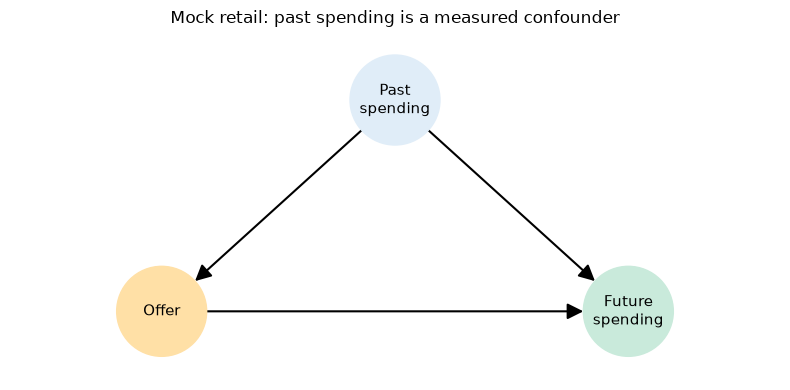

In [6]:
rng = np.random.default_rng(SEED)
mock_n = 4000
past_spend = rng.uniform(0, 500, mock_n)
propensity = 1 / (1 + np.exp(-(past_spend - 250) / 100))
offer = rng.binomial(1, propensity)
noise = rng.normal(0, 10, mock_n)
future_without_offer = 30 + 0.3 * past_spend + noise
future_with_offer = future_without_offer + 20
mock = pd.DataFrame({
    'past_spend': past_spend, 'offer': offer,
    'future_spend': np.where(offer == 1, future_with_offer, future_without_offer)})
assert np.allclose(future_with_offer - future_without_offer, 20)
assert 0 < propensity.min() < propensity.max() < 1
print(f'Simulated assignment probabilities: {propensity.min():.3f} to {propensity.max():.3f}')
display(mock.groupby('offer').agg(
    rows=('offer', 'size'), mean_past_spend=('past_spend', 'mean'),
    mean_future_spend=('future_spend', 'mean')).round(2))

mock_graph = nx.DiGraph([
    ('past_spend', 'offer'), ('past_spend', 'future_spend'), ('offer', 'future_spend')])
assert nx.is_directed_acyclic_graph(mock_graph)
fig, ax = plt.subplots(figsize=(8, 4))
nx.draw_networkx(mock_graph,
                 pos={'past_spend': (0.5, 1), 'offer': (0, 0), 'future_spend': (1, 0)},
                 ax=ax, node_size=4200, node_color=['#e0edf8', '#ffe0a6', '#c9eadb'],
                 labels={'past_spend': 'Past\nspending', 'offer': 'Offer', 'future_spend': 'Future\nspending'},
                 arrowsize=24, font_size=11, width=1.5)
ax.set_title('Mock retail: past spending is a measured confounder')
ax.margins(0.25)
ax.axis('off')
plt.tight_layout()
fig.savefig(OUTPUT / 'mock_retail_dag.png', dpi=160, bbox_inches='tight')
plt.show()

## 8. Block the mock backdoor path with DoWhy

The side path is `offer <- past_spend -> future_spend`. Adjusting for `past_spend` blocks it. In this simulation, the adjusted effect is identified by:

$$\int \{E[Y\mid offer=1,H=h]-E[Y\mid offer=0,H=h]\}\,p(h)\,dh,$$

where $H$ is `past_spend`. Our correct linear simulation lets DoWhy use linear regression for this teaching check. We also solve the same regression independently using NumPy to verify the result.

In [7]:
mock_model = CausalModel(data=mock, treatment='offer', outcome='future_spend', graph=mock_graph)
mock_estimand = mock_model.identify_effect()
mock_adjustment = list(mock_estimand.get_backdoor_variables())
assert set(mock_adjustment) == {'past_spend'}
mock_estimate = mock_model.estimate_effect(
    mock_estimand, method_name='backdoor.linear_regression',
    control_value=0, treatment_value=1, effect_modifiers=[])

naive = (mock.loc[mock.offer == 1, 'future_spend'].mean()
         - mock.loc[mock.offer == 0, 'future_spend'].mean())
design = np.column_stack([np.ones(len(mock)), mock.offer, mock.past_spend])
independent_ols = np.linalg.lstsq(design, mock.future_spend.to_numpy(), rcond=None)[0][1]
assert np.isclose(float(mock_estimate.value), independent_ols, atol=1e-9)

mock_comparison = pd.DataFrame({
    'Method': ['Known simulation truth', 'Unadjusted group difference', 'DoWhy adjusted for past_spend'],
    'Incremental dollars': [20.0, float(naive), float(mock_estimate.value)]})
print('DoWhy adjustment set:', mock_adjustment)
display(mock_comparison.round(3))
print(f'Adjusted estimate minus known truth: ${float(mock_estimate.value) - 20:.3f}')
print('The adjusted result need not equal $20 exactly because this is a finite noisy sample.')

DoWhy adjustment set: ['past_spend']


,Method,Incremental dollars
0,Known simulation truth,20.000
1,Unadjusted group difference,70.792
2,DoWhy adjusted for past_spend,19.880


Adjusted estimate minus known truth: $-0.120
The adjusted result need not equal $20 exactly because this is a finite noisy sample.


## 9. Assumptions, limits, and the next project step

Both examples need well-defined treatments (**consistency**), no spillovers between customers (**no interference**), and a nonzero chance of receiving each compared treatment (**overlap**). Hillstrom additionally uses its documented random assignment. In the mock example, identification assumes `past_spend` is sufficient to block treatment/outcome confounding, as specified in our generator.

The DAG is a set of assumptions, not a proof learned from this CSV. Its arrows from customer characteristics represent a simplified plausible outcome model. The six empty Hillstrom adjustment sets depend on random assignment; they would not automatically be correct for targeted observational campaigns.

Passing a graph check or a later DoWhy refutation cannot prove that every hidden confounder is absent. The mock example illustrates a **measured** confounder, not detection or removal of an unknown hidden variable.

The next step is the Week 2 EconML model using the prepared baseline and engineered features, treatment kept separate, training-only fitting/cross-fitting, and held-out Qini/uplift evaluation. This graph notebook does not claim to have estimated true individual treatment effects or optimized a budget.

In [8]:
# Save a small, inspectable audit trail. No existing processed files are overwritten.
def graph_as_dot(graph):
    lines = ['digraph {']
    lines += [f'    "{source}" -> "{target}";' for source, target in graph.edges]
    return '\n'.join(lines + ['}'])

for outcome in OUTCOMES:
    (OUTPUT / f'hillstrom_{outcome}_dag.dot').write_text(graph_as_dot(make_email_graph(outcome)))
(OUTPUT / 'mock_retail_dag.dot').write_text(graph_as_dot(mock_graph))
(OUTPUT / 'mock_estimand.txt').write_text(str(mock_estimand))
mock.to_csv(OUTPUT / 'mock_retail_teaching_only.csv', index=False)
real_effects.to_csv(OUTPUT / 'training_average_effect_checks.csv', index=False)
summary = {
    'seed': SEED,
    'dowhy_version': dowhy.__version__,
    'source_sha256': hashlib.sha256(raw_path.read_bytes()).hexdigest(),
    'rows': len(data), 'training_rows': len(train), 'reserved_test_rows': len(test_ids),
    'baseline_variables': BASELINE,
    'real_treatment': 'randomized email assignment',
    'real_backdoor_adjustment': [],
    'real_comparisons': real_rows,
    'mock': {'rows': len(mock), 'measured_confounder': 'past_spend',
             'adjustment': mock_adjustment, 'known_effect': 20.0,
             'unadjusted_difference': float(naive), 'adjusted_effect': float(mock_estimate.value)},
    'checks': {'six_real_identifications': len(identification_rows) == 6,
               'real_dowhy_equals_group_means': True, 'mock_dowhy_equals_numpy_ols': True,
               'graphs_acyclic': True, 'synthetic_data_kept_separate': True},
}
(OUTPUT / 'causal_graph_review.json').write_text(json.dumps(summary, indent=2, allow_nan=False))
print('Saved DAG images, DOT graphs, estimands, and checks under results/causal_graphs/.')
print('All graph and independent numerical consistency checks passed.')

Saved DAG images, DOT graphs, estimands, and checks under results/causal_graphs/.
All graph and independent numerical consistency checks passed.


## Explain it to your manager or friends

**Real data:** “We have three shuffled email groups. We compare each email with no email, so previous shopping habits did not decide the treatment. We check visits, purchases, and spending separately.”

**Mock shop:** “The shop gives more offers to big spenders. Those people already spend more. The raw comparison wrongly gives the offer credit for that difference. Our graph spots the side path through previous spending, and DoWhy adjusts for it.”

**Why two examples?** The images ask for a mock retail DAG with a confounder; the guide selects a real randomized email dataset. Keeping them separate satisfies both requirements without inventing confounding or discounts in Hillstrom.

## References checked

- Supplied project images: Week 1 causal graphing with DoWhy for mock retail, identifying confounders, treatments, and outcomes.
- Supplied *EconoCausal Project Guide*: sections 4-6 and 9, including the Hillstrom email adaptation and continued propensity/refutation tasks.
- [Hillstrom's original experiment and variable definitions](https://blog.minethatdata.com/2008/03/minethatdata-e-mail-analytics-and-data.html).
- [DoWhy: specifying graphs using domain knowledge](https://www.pywhy.org/dowhy/v0.14/user_guide/modeling_causal_relations/specifying_causal_graph.html).
- [DoWhy: backdoor identification](https://www.pywhy.org/dowhy/v0.14/user_guide/causal_tasks/estimating_causal_effects/identifying_causal_effect/backdoor.html).